In [5]:
import torch
import torchvision
from torchvision import transforms
from torchvision.models.segmentation import deeplabv3_resnet50

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


torch: 2.6.0
torchvision: 0.19.1+cu121
CUDA available: True
GPU: Tesla T4


In [ ]:


import os, math, time, json, argparse
from pathlib import Path

import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.models.segmentation import deeplabv3_resnet50
from tqdm import tqdm

# Utilities
def seed_everything(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def pil_open_rgb(path):
    return Image.open(path).convert("RGB")

def pil_open_mask(path):
    # Loads mask as L (0..255), later we threshold to {0,1}
    return Image.open(path).convert("L")

def ensure_dir(p):
    Path(p).mkdir(parents=True, exist_ok=True)

# model dataset
class WoundSegDataset(Dataset):
    
    def __init__(self, images_dir, masks_dir, size=512, aug=False):
        self.images_dir = Path(images_dir)
        self.masks_dir = Path(masks_dir)
        self.size = size
        self.aug = aug

        # Index by image files only
        exts = (".png", ".jpg", ".jpeg")
        self.images = [p for p in self.images_dir.iterdir() if p.suffix.lower() in exts]
        self.images.sort()

        self.to_tensor_img = transforms.ToTensor()  # 0..1
        self.resize_img = transforms.Resize(
            (size, size),
            interpolation=transforms.InterpolationMode.BILINEAR,
            antialias=True
        )
        self.resize_mask = transforms.Resize(
            (size, size),
            interpolation=transforms.InterpolationMode.NEAREST
        )

        # light augmentations (on PIL) — safe for medical images
        self.color_jitter = transforms.ColorJitter(
            brightness=0.15, contrast=0.15,
            saturation=0.05, hue=0.02
        )
        self.hflip = transforms.RandomHorizontalFlip(p=0.5)
        self.vflip = transforms.RandomVerticalFlip(p=0.2)

    def _find_mask_path(self, img_path: Path):
        stem = img_path.stem
        # try common mask extensions
        for ext in [".png", ".jpg", ".jpeg", ".PNG", ".JPG", ".JPEG"]:
            cand = self.masks_dir / f"{stem}{ext}"
            if cand.exists():
                return cand
        # some kaggle sets use *_mask
        for ext in [".png", ".jpg", ".jpeg", ".PNG", ".JPG", ".JPEG"]:
            cand = self.masks_dir / f"{stem}_mask{ext}"
            if cand.exists():
                return cand
        raise FileNotFoundError(f"No mask found for {img_path.name}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        mask_path = self._find_mask_path(img_path)

        img = pil_open_rgb(img_path)
        msk = pil_open_mask(mask_path)

        # Resize first (consistent)
        img = self.resize_img(img)
        msk = self.resize_mask(msk)

        if self.aug:
            # Random horizontal/vertical flips applied synchronously to img & mask
            if torch.rand(1).item() < 0.5:
                img = transforms.functional.hflip(img)
                msk = transforms.functional.hflip(msk)
            if torch.rand(1).item() < 0.2:
                img = transforms.functional.vflip(img)
                msk = transforms.functional.vflip(msk)
            # Light color jitter on image only
            img = self.color_jitter(img)

        img_tensor = self.to_tensor_img(img)  # CxHxW float 0..1
        msk_tensor = torch.from_numpy((np.array(msk) > 127).astype(np.float32))  # HxW
        msk_tensor = msk_tensor.unsqueeze(0)  # 1xHxW

        return img_tensor, msk_tensor, str(img_path.name)

# loss
class DiceBCELoss(nn.Module):
    def __init__(self, smooth=1.0, bce_weight=0.5):
        super().__init__()
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()
        self.w = bce_weight

    def forward(self, logits, targets):
        # logits: Bx1xHxW; targets: Bx1xHxW (0/1)
        bce = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        num = 2 * (probs * targets).sum(dim=(2,3)) + self.smooth
        den = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3)) + self.smooth
        dice = (num / den).mean()
        loss = self.w * bce + (1 - self.w) * (1 - dice)
        return loss, dice

def iou_score(logits, targets, thresh=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > thresh).float()
    inter = (preds * targets).sum(dim=(2,3))
    union = (preds + targets - preds*targets).sum(dim=(2,3)) + eps
    iou = (inter / union).mean()
    return iou

# Model
def build_model():
    model = deeplabv3_resnet50(weights="DEFAULT")  # torchvision>=0.13
    # Replace classifier for 1-class segmentation
    model.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
    return model

# Training / Validation
def run_epoch(model, loader, optimizer, device, scaler=None, train=True):
    model.train(train)
    loss_meter, dice_meter, iou_meter = 0.0, 0.0, 0.0
    crit = DiceBCELoss(smooth=1.0, bce_weight=0.5)

    pbar = tqdm(loader, leave=False)
    for imgs, masks, _ in pbar:
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if train:
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=scaler is not None):
                out = model(imgs)['out']
                loss, dice = crit(out, masks)
                iou = iou_score(out, masks)
            if scaler is not None:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()
        else:
            with torch.no_grad():
                out = model(imgs)['out']
                loss, dice = crit(out, masks)
                iou = iou_score(out, masks)

        loss_meter += loss.item()
        dice_meter += dice.item()
        iou_meter += iou.item()
        pbar.set_description(
            f"{'Train' if train else 'Val'} "
            f"loss:{loss_meter / (pbar.n+1):.4f} "
            f"dice:{dice_meter / (pbar.n+1):.4f} "
            f"iou:{iou_meter / (pbar.n+1):.4f}"
        )

    n = len(loader)
    return loss_meter/n, dice_meter/n, iou_meter/n

# Prediction
def export_predictions(model, images_dir, out_dir, device, size=512, thresh=0.5):
    ensure_dir(out_dir)
    model.eval()
    resize_img = transforms.Resize(
        (size, size),
        interpolation=transforms.InterpolationMode.BILINEAR,
        antialias=True
    )
    to_tensor = transforms.ToTensor()

    exts = (".png", ".jpg", ".jpeg")
    img_paths = [p for p in Path(images_dir).iterdir() if p.suffix.lower() in exts]
    for p in tqdm(img_paths, desc="Exporting preds"):
        img = pil_open_rgb(p)
        img_r = resize_img(img)
        x = to_tensor(img_r).unsqueeze(0).to(device)
        with torch.no_grad():
            out = model(x)['out']
            prob = torch.sigmoid(out)[0,0].cpu().numpy()
        mask = (prob >= thresh).astype(np.uint8) * 255
        Image.fromarray(mask).save(Path(out_dir) / f"{p.stem}.png")

-

# image paths
#CHANGE THESE PATHS AS NEEDED
IMAGES_DIR = "/home/sagemaker-user/train_images/train_images" 
MASKS_DIR  = "/home/sagemaker-user/train_masks/train_masks"
OUT_DIR    = "/home/sagemaker-user/wound_seg_run"

SIZE       = 512      
EPOCHS     = 40      
BATCH_SIZE = 4       
LR         = 1e-4
VAL_SPLIT  = 0.15
USE_AMP    = True     
SEED       = 42

print("Notebook runner starting...")
print("Config:")
print(f"  size={SIZE}, epochs={EPOCHS}, batch_size={BATCH_SIZE}")

seed_everything(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

full = WoundSegDataset(IMAGES_DIR, MASKS_DIR, size=SIZE, aug=True)
print(f"Found {len(full)} images in {IMAGES_DIR}")
if len(full) == 0:
    raise RuntimeError("Dataset is empty — check IMAGES_DIR/MASKS_DIR and filenames.")

n_total = len(full)
n_val = max(1, int(math.ceil(n_total * VAL_SPLIT)))
n_train = n_total - n_val
train_ds, val_ds = random_split(
    full,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED)
)
val_ds.dataset.aug = False

NUM_WORKERS = 4
PIN_MEMORY  = True

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

model = build_model().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler() if (USE_AMP and device == "cuda") else None

run_dir = Path(OUT_DIR)
ckpt_dir = run_dir / "checkpoints"
pred_dir = run_dir / "preds"
ensure_dir(ckpt_dir)
ensure_dir(pred_dir)

best_val = -1.0
history = []

print("Starting training loop...")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_dice, tr_iou = run_epoch(
        model, train_loader, optimizer, device, scaler, train=True
    )
    va_loss, va_dice, va_iou = run_epoch(
        model, val_loader, optimizer, device, scaler=None, train=False
    )
    dt = time.time() - t0

    history.append({
        "epoch": epoch,
        "train_loss": tr_loss,
        "train_dice": tr_dice,
        "train_iou": tr_iou,
        "val_loss": va_loss,
        "val_dice": va_dice,
        "val_iou": va_iou,
        "seconds": dt
    })

    print(f"[Epoch {epoch}/{EPOCHS}] "
          f"train loss {tr_loss:.4f} dice {tr_dice:.4f} iou {tr_iou:.4f} | "
          f"val loss {va_loss:.4f} dice {va_dice:.4f} iou {va_iou:.4f} | "
          f"{dt:.1f}s")

    if va_dice > best_val:
        best_val = va_dice
        best_path = ckpt_dir / "best_deeplabv3.pth"
        torch.save({
            "model": model.state_dict(),
            "epoch": epoch,
            "val_dice": best_val,
            "config": {
                "size": SIZE,
                "epochs": EPOCHS,
                "batch_size": BATCH_SIZE,
                "lr": LR,
                "val_split": VAL_SPLIT,
                "use_amp": USE_AMP,
                "seed": SEED
            }
        }, best_path)
        print(f"  ✅ Saved best checkpoint: {best_path} (val_dice={best_val:.4f})")

# Save training history
ensure_dir(run_dir)
with open(run_dir / "history.json", "w") as f:
    json.dump(history, f, indent=2)

print("Training complete.")
print(f"Best val Dice: {best_val:.4f}")
print(f"Checkpoints in: {ckpt_dir}")


Notebook runner starting...
Config:
  size=512, epochs=40, batch_size=4
Device: cuda
Found 2208 images in /home/sagemaker-user/train_images/train_images


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /home/sagemaker-user/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth
100%|██████████| 161M/161M [00:00<00:00, 184MB/s]  
/tmp/ipykernel_3035/4006227912.py:295: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if (USE_AMP and device == "cuda") else None


Starting training loop...


  0%|          | 0/469 [00:00<?, ?it/s]/tmp/ipykernel_3035/4006227912.py:178: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=scaler is not None):
                                                                                           

[Epoch 1/40] train loss 0.4443 dice 0.3107 iou 0.5626 | val loss 0.2778 dice 0.5023 iou 0.6420 | 464.5s
  ✅ Saved best checkpoint: /home/sagemaker-user/wound_seg_run/checkpoints/best_deeplabv3.pth (val_dice=0.5023)


[Epoch 2/40] train loss 0.2164 dice 0.6219 iou 0.6900 | val loss 0.1789 dice 0.6830 iou 0.6849 | 465.5s
  ✅ Saved best checkpoint: /home/sagemaker-user/wound_seg_run/checkpoints/best_deeplabv3.pth (val_dice=0.6830)


... (34 outputs left out)

[Epoch 37/40] train loss 0.0292 dice 0.9509 iou 0.9132 | val loss 0.0876 dice 0.8641 iou 0.7867 | 463.3s


[Epoch 38/40] train loss 0.0235 dice 0.9600 iou 0.9279 | val loss 0.0869 dice 0.8690 iou 0.7923 | 462.7s


[Epoch 39/40] train loss 0.0203 dice 0.9653 iou 0.9360 | val loss 0.0859 dice 0.8716 iou 0.7953 | 463.2s


[Epoch 40/40] train loss 0.0194 dice 0.9666 iou 0.9381 | val loss 0.0820 dice 0.8758 iou 0.7993 | 462.7s
  ✅ Saved best checkpoint: /home/sagemaker-user/wound_seg_run/checkpoints/best_deeplabv3.pth (val_dice=0.8758)
Training complete.
Best val Dice: 0.8758
Checkpoints in: /home/sagemaker-user/wound_seg_run/checkpoints


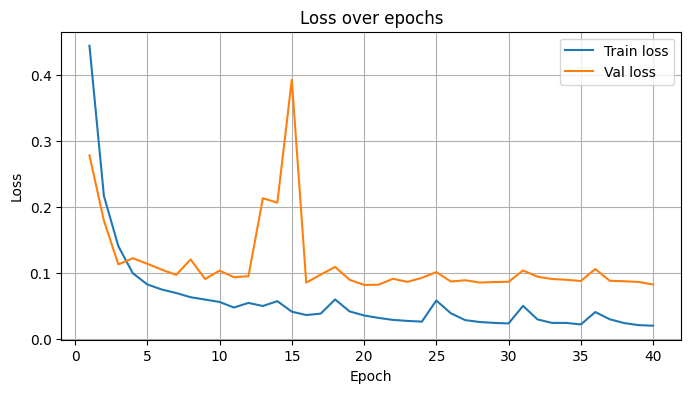

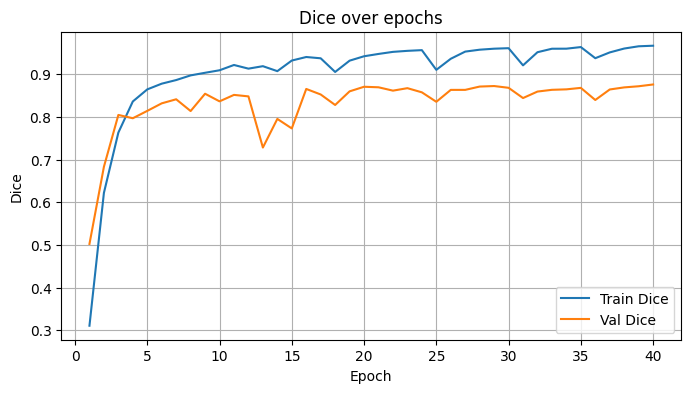

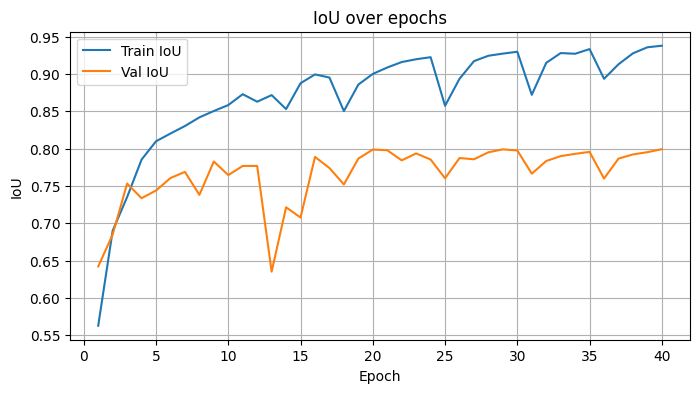

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

OUT_DIR = "wound_seg_run"  # same as before
hist_path = Path(OUT_DIR) / "history.json"

with open(hist_path, "r") as f:
    history = json.load(f)

epochs     = [h["epoch"] for h in history]
train_loss = [h["train_loss"] for h in history]
val_loss   = [h["val_loss"] for h in history]
train_dice = [h["train_dice"] for h in history]
val_dice   = [h["val_dice"] for h in history]
train_iou  = [h["train_iou"] for h in history]
val_iou    = [h["val_iou"] for h in history]

plt.figure(figsize=(8,4))
plt.plot(epochs, train_loss, label="Train loss")
plt.plot(epochs, val_loss,   label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over epochs")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,4))
plt.plot(epochs, train_dice, label="Train Dice")
plt.plot(epochs, val_dice,   label="Val Dice")
plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.title("Dice over epochs")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,4))
plt.plot(epochs, train_iou, label="Train IoU")
plt.plot(epochs, val_iou,   label="Val IoU")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("IoU over epochs")
plt.legend()
plt.grid(True)
plt.show()


In [4]:
import torch
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms

IMAGES_DIR = "/home/sagemaker-user/train_images"
MASKS_DIR  = "/home/sagemaker-user/train_masks"
CKPT_PATH  = "/home/sagemaker-user/wound_seg_run/checkpoints/best_deeplabv3.pth"

SIZE   = 512
device = "cuda" if torch.cuda.is_available() else "cpu"

resize_img = transforms.Resize((SIZE, SIZE))
to_tensor  = transforms.ToTensor()


In [6]:
import torch.nn as nn
from torchvision.models.segmentation import deeplabv3_resnet50

def build_model():
    # aux_loss=True so we get aux_classifier like during training
    model = deeplabv3_resnet50(weights=None, aux_loss=True)
    # Replace main classifier head with 1-channel output
    model.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
    return model

model = build_model().to(device)

ckpt = torch.load(CKPT_PATH, map_location=device)
# allow extra keys (like aux_classifier) just in case
missing, unexpected = model.load_state_dict(ckpt["model"], strict=False)
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)

model.eval()
print("Loaded model. Best val dice:", ckpt.get("val_dice"))


Missing keys: []
Unexpected keys: []
Loaded model. Best val dice: 0.8758110605090498


/tmp/ipykernel_3035/2272533657.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(CKPT_PATH, map_location=device)


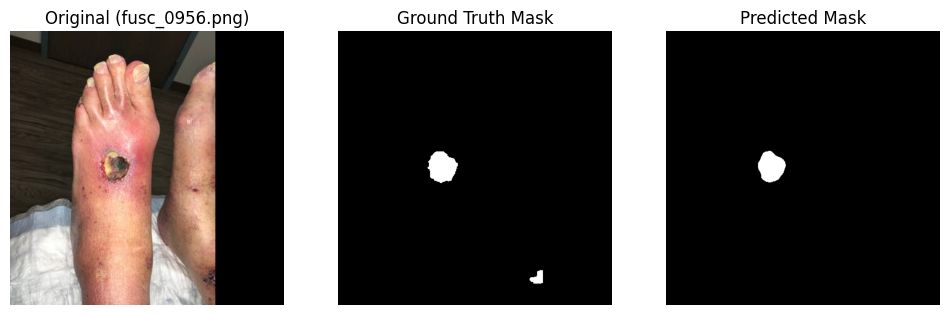

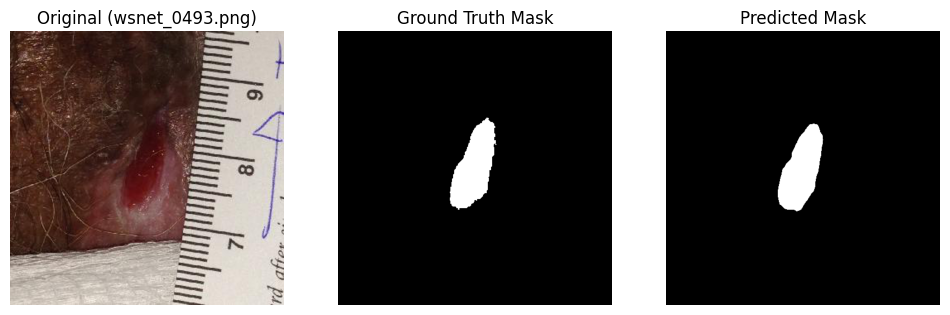

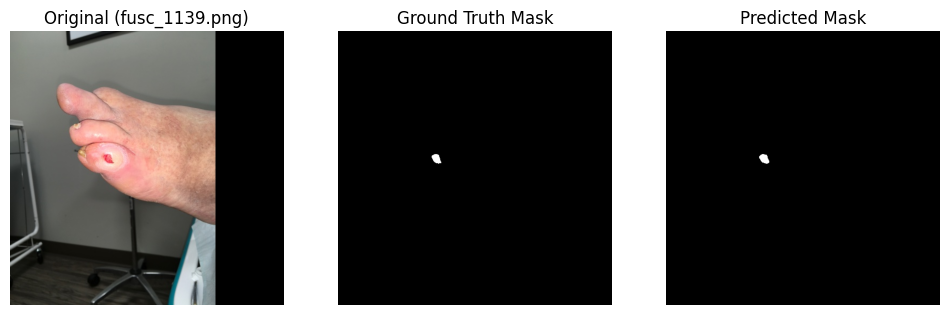

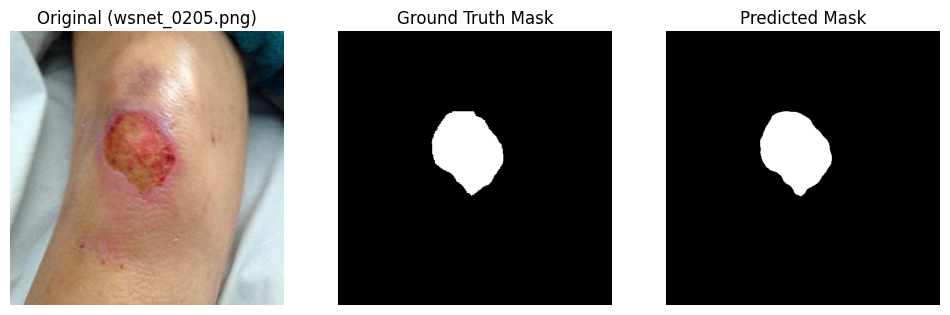

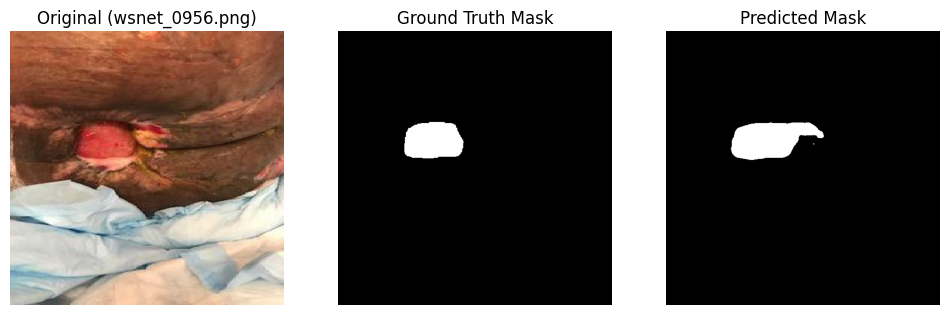

In [8]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
import torch
import numpy as np
from pathlib import Path

model.eval()

N = 5  # how many examples to show

subset = val_ds                 # Subset
base_ds = subset.dataset        # underlying WoundSegDataset

# Random indices inside the subset
subset_idxs = torch.randint(0, len(subset), (N,))

for sid in subset_idxs:
    sid = int(sid)

    # Map subset index -> original dataset index
    global_idx = subset.indices[sid]

    # Get actual paths from the base dataset
    img_path = base_ds.images[global_idx]
    mask_path = base_ds._find_mask_path(img_path)

    # Load original image + mask
    img_pil  = pil_open_rgb(img_path)
    mask_pil = pil_open_mask(mask_path)

    # Preprocess for model (same resize as training)
    inp_pil = base_ds.resize_img(img_pil)
    x = TF.to_tensor(inp_pil).unsqueeze(0).to(device)

    with torch.no_grad():
        out = model(x)["out"]
        prob = torch.sigmoid(out)[0, 0].cpu().numpy()
        pred_np = (prob > 0.5).astype(np.uint8)

    # For display: convert PIL → numpy
    img_np  = np.array(inp_pil)                 # (H,W,3)
    mask_np = np.array(base_ds.resize_mask(mask_pil)) > 127  # bool mask

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(img_np)
    plt.title(f"Original ({img_path.name})")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(mask_np, cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(pred_np, cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.show()

In [9]:
import zipfile

zip_path = "/home/sagemaker-user/WoundDB.zip"
extract_to = "/home/sagemaker-user/WoundDB"

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_to)

print("Extracted WoundDB →", extract_to)

Extracted WoundDB → /home/sagemaker-user/WoundDB


In [12]:
import zipfile

zip_path = "/home/sagemaker-user/AZH.zip"
extract_to = "/home/sagemaker-user/AZH"

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_to)

print("Extracted AZH →", extract_to)

Extracted AZH → /home/sagemaker-user/AZH


In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from torchvision import transforms
import torch
import numpy as np

INPUT_DIR  = "/home/sagemaker-user/AZH/AZH"       
OUTPUT_DIR = "/home/sagemaker-user/AZH_masks"    

THRESH = 0.5        # probability threshold for mask
SIZE   = 512        # use same size as training 

def export_masks_for_folder(input_dir, output_dir, size=SIZE, thresh=THRESH):
    input_dir  = Path(input_dir)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    exts = (".png", ".jpg", ".jpeg", ".tif", ".tiff")
    img_paths = sorted([p for p in input_dir.iterdir() if p.suffix.lower() in exts])

    print(f"Found {len(img_paths)} images in {input_dir}")
    if not img_paths:
        return

    resize_img = transforms.Resize((size, size))
    to_tensor  = transforms.ToTensor()

    model.eval()
    with torch.no_grad():
        for p in tqdm(img_paths, desc="Exporting masks"):
            # load + resize
            img = pil_open_rgb(p)
            img_r = resize_img(img)

            x = to_tensor(img_r).unsqueeze(0).to(device)

            # forward pass
            out = model(x)["out"]
            prob = torch.sigmoid(out)[0, 0].cpu().numpy()

            # binarize
            mask = (prob > thresh).astype(np.uint8) * 255

            # save as PNG
            out_path = output_dir / f"{p.stem}.png"
            Image.fromarray(mask).save(out_path)

    print("Done. Masks saved to:", output_dir)

export_masks_for_folder(INPUT_DIR, OUTPUT_DIR)

Found 930 images in /home/sagemaker-user/AZH/AZH


Exporting masks: 100%|██████████| 930/930 [01:29<00:00, 10.34it/s]

Done. Masks saved to: /home/sagemaker-user/AZH_masks


In [ ]:
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from torchvision import transforms
import torch
import numpy as np

INPUT_DIR  = "/home/sagemaker-user/WoundDB/WoundDB"        
OUTPUT_DIR = "/home/sagemaker-user/WOundDB_masks"   

THRESH = 0.5        # probability threshold for mask
SIZE   = 512        # use same size as training (change if you trained with a different SIZE)

def export_masks_for_folder(input_dir, output_dir, size=SIZE, thresh=THRESH):
    input_dir  = Path(input_dir)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    exts = (".png", ".jpg", ".jpeg", ".tif", ".tiff")
    img_paths = sorted([p for p in input_dir.iterdir() if p.suffix.lower() in exts])

    print(f"Found {len(img_paths)} images in {input_dir}")
    if not img_paths:
        return

    resize_img = transforms.Resize((size, size))
    to_tensor  = transforms.ToTensor()

    model.eval()
    with torch.no_grad():
        for p in tqdm(img_paths, desc="Exporting masks"):
            # load + resize
            img = pil_open_rgb(p)
            img_r = resize_img(img)

            x = to_tensor(img_r).unsqueeze(0).to(device)

            # forward pass
            out = model(x)["out"]
            prob = torch.sigmoid(out)[0, 0].cpu().numpy()

            # binarize
            mask = (prob > thresh).astype(np.uint8) * 255

            # save as PNG
            out_path = output_dir / f"{p.stem}.png"
            Image.fromarray(mask).save(out_path)

    print("Done. Masks saved to:", output_dir)

export_masks_for_folder(INPUT_DIR, OUTPUT_DIR)

Found 79 images in /home/sagemaker-user/WoundDB/WoundDB


Exporting masks: 100%|██████████| 79/79 [00:07<00:00, 10.39it/s]

Done. Masks saved to: /home/sagemaker-user/WOundDB_masks
